# Lab 14-04 · Computer Arithmetic and Number Formats

Companion to [chapter 14-04](../../chapters/14-04-computer-arithmetic-and-number-formats.md). Four parts: integer corner cases and division by constants; a floating-point adder built from integers; summation error; and quantization. Part 1 needs the LLVM tools (see the [lab handout](README.md)). Run the cells in order.

In [1]:
import math, random, re, struct, subprocess, sys
from fractions import Fraction as Fr
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../verify').resolve()))
from _rv32 import run_function, sx, tool, M32
f32 = np.float32
bits = lambda x: struct.unpack('<I', struct.pack('<f', float(x)))[0]
from_bits = lambda b: struct.unpack('<f', struct.pack('<I', b))[0]

## Part 1 · Integers on the simulator, and division by constants

**Predict first:** what do DIV and REM return for 7 ÷ 0 and for −2³¹ ÷ −1?

In [2]:
OPS = '''    .text
    .globl t
t:  mul a2, a0, a1
    mulh a3, a0, a1
    mulhu a4, a0, a1
    div a5, a0, a1
    rem a6, a0, a1
    ret
'''
for a, b in [(-3, 5), (7, 0), (-2**31, -1), (-7, 2), (7, -2)]:
    x = run_function({'t.s': OPS}, 't', [a, b], m=True)['sim'].x
    print(f'a = {a:12d}, b = {b:3d}:  MUL {x[12]:#010x}  MULH {x[13]:#010x}  MULHU {x[14]:#010x}  DIV {sx(x[15], 32):12d}  REM {sx(x[16], 32):4d}')

a =           -3, b =   5:  MUL 0xfffffff1  MULH 0xffffffff  MULHU 0x00000004  DIV            0  REM   -3
a =            7, b =   0:  MUL 0x00000000  MULH 0x00000000  MULHU 0x00000000  DIV           -1  REM    7
a =  -2147483648, b =  -1:  MUL 0x80000000  MULH 0x00000000  MULHU 0x7fffffff  DIV  -2147483648  REM    0
a =           -7, b =   2:  MUL 0xfffffff2  MULH 0xffffffff  MULHU 0x00000001  DIV           -3  REM   -1


a =            7, b =  -2:  MUL 0xfffffff2  MULH 0xffffffff  MULHU 0x00000006  DIV           -3  REM    1


In [3]:
def magic(d):
    k = 0
    while True:
        M = -(-(2 ** (32 + k)) // d)
        if d * M - 2 ** (32 + k) <= 2 ** k:
            return M, 32 + k
        k += 1

def clang_div(d):
    out = subprocess.run([tool('clang'), '--target=riscv32', '-march=rv32im', '-mabi=ilp32', '-O2', '-S', '-x', 'c', '-', '-o', '-'],
                         input=f'unsigned f(unsigned x) {{ return x / {d}; }}', capture_output=True, text=True, check=True).stdout
    return [ln.strip() for ln in out.splitlines() if re.match(r'\s+(lui|addi|mulhu|sub|srli|add)\b', ln)]

for d in (3, 7, 10, 1000):
    M, sh = magic(d)
    print(f'd = {d:5d}: M = {M:#x} ({"33 bits" if M >= 2**32 else "32 bits"}), shift {sh}')
    print('          clang:', ' ; '.join(clang_div(d)))

d =     3: M = 0xaaaaaaab (32 bits), shift 33
          clang: lui	a1, 699051 ; addi	a1, a1, -1365 ; mulhu	a0, a0, a1 ; srli	a0, a0, 1
d =     7: M = 0x124924925 (33 bits), shift 35
          clang: lui	a1, 149797 ; addi	a1, a1, -1755 ; mulhu	a1, a0, a1 ; sub	a0, a0, a1 ; srli	a0, a0, 1 ; add	a0, a0, a1 ; srli	a0, a0, 2
d =    10: M = 0xcccccccd (32 bits), shift 35
          clang: lui	a1, 838861 ; addi	a1, a1, -819 ; mulhu	a0, a0, a1 ; srli	a0, a0, 3
d =  1000: M = 0x10624dd3 (32 bits), shift 38
          clang: lui	a1, 67109 ; addi	a1, a1, -557 ; mulhu	a0, a0, a1 ; srli	a0, a0, 6


## Part 2 · A floating-point adder made of integers

Implement addition of two positive normal FP32 numbers. Keep three extra bits below the significand (guard, round, sticky), add, renormalize, and round to nearest even.

**Predict first:** if the sticky bit is dropped, will the adder still always agree with the hardware?

In [4]:
def add_f32(x, y, sticky=True):
    ex, ey = x >> 23 & 0xFF, y >> 23 & 0xFF
    mx, my = (x & 0x7FFFFF) | 0x800000, (y & 0x7FFFFF) | 0x800000
    if (ex, mx) < (ey, my):
        ex, ey, mx, my = ey, ex, my, mx
    d = ex - ey
    my3 = my << 3                                   # guard, round, sticky positions
    if d:
        shifted = my3 >> d if d < 27 else 0
        lost = my3 & ((1 << d) - 1) if d < 27 else my3
        my3 = shifted | (1 if (sticky and lost) else 0)
    m, e = (mx << 3) + my3, ex
    if m >> 27:                                     # carry out of the significand
        m, e = (m >> 1) | ((m & 1) if sticky else 0), e + 1
    keep, low = m >> 3, m & 7
    if low > 4 or (low == 4 and keep & 1):          # round to nearest, ties to even
        keep += 1
        if keep >> 24:
            keep, e = keep >> 1, e + 1
    return (e << 23) | (keep & 0x7FFFFF)

rnd = random.Random(1)
mism = {True: 0, False: 0}
for i in range(100_000):
    ea = rnd.randint(100, 150); eb = ea - rnd.randint(0, 3) if i % 4 == 0 else rnd.randint(100, 150)
    xa, xb = (ea << 23) | rnd.getrandbits(23), (eb << 23) | rnd.getrandbits(23)
    hw = bits(f32(from_bits(xa)) + f32(from_bits(xb)))
    for st in (True, False):
        mism[st] += add_f32(xa, xb, st) != hw
print('mismatches with sticky:', mism[True], '   without sticky:', mism[False])
for a, b in [(1.0, 2**-24), (1.0, 1.5 * 2**-24), (1 + 2**-23, 2**-24)]:
    print(f'{a!r:>20} + {b!r:<24} -> {add_f32(bits(a), bits(b)):#010x}')

mismatches with sticky: 0    without sticky: 2783
                 1.0 + 5.960464477539063e-08    -> 0x3f800000
                 1.0 + 8.940696716308594e-08    -> 0x3f800001
  1.0000001192092896 + 5.960464477539063e-08    -> 0x3f800002


## Part 3 · How summation error grows

Sum the FP32 value of 0.1 up to $n = 10^6$ times, in FP32, three ways, and plot the relative error against $n$.

**Predict first:** does the sequential error grow like $n$ or like $\sqrt{n}$?

n =    10000: sequential -0.0097%   pairwise -1.49e-08   Kahan -1.49e-08
n =   100000: sequential -0.0144%   pairwise -1.49e-08   Kahan -1.49e-08
n =  1000000: sequential +0.9583%   pairwise -9.30e-08   Kahan -1.49e-08


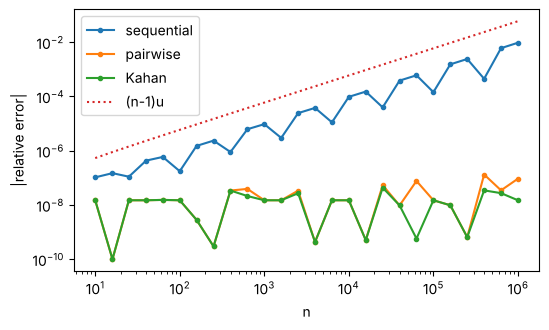

In [5]:
X = f32(0.1)
from functools import lru_cache
@lru_cache(maxsize=None)
def pairwise(n):
    return X if n == 1 else f32(pairwise(n // 2) + pairwise(n - n // 2))

ns = sorted({int(round(10 ** e)) for e in np.linspace(1, 6, 26)}); targets = set(ns)
seq, kah = {}, {}
s = k = c = f32(0)
for i in range(1, ns[-1] + 1):
    s = f32(s + X); y = f32(X - c); t = f32(k + y); c = f32(f32(t - k) - y); k = t
    if i in targets: seq[i], kah[i] = s, k
rel = lambda v, n: float((Fr(float(v)) - Fr(float(X)) * n) / (Fr(float(X)) * n))
for n in (10**4, 10**5, 10**6):
    print(f'n = {n:8d}: sequential {100 * rel(seq[n], n):+.4f}%   pairwise {rel(pairwise(n), n):+.2e}   Kahan {rel(kah[n], n):+.2e}')
plt.figure(figsize=(6, 3.4))
for lab, vals in (('sequential', seq), ('pairwise', {n: pairwise(n) for n in ns}), ('Kahan', kah)):
    plt.loglog(ns, [max(abs(rel(vals[n], n)), 1e-10) for n in ns], 'o-', ms=3, label=lab)
plt.loglog(ns, [(n - 1) * 2.0**-24 for n in ns], ':', label='(n-1)u')
plt.xlabel('n'); plt.ylabel('|relative error|'); plt.legend(); plt.show()

## Part 4 · Quantization: INT8, INT4 and block-scaled FP4

Quantize 4096 Gaussian samples. INT$b$ uses one symmetric scale for the whole tensor. MX-style FP4 uses blocks of 32 with a power-of-two scale (the OCP rule of §3.5) and E2M1 elements.

In [6]:
g = np.random.default_rng(0)
data = g.standard_normal(4096)
E2M1 = [0, 0.5, 1, 1.5, 2, 3, 4, 6]
def to_e2m1(x):
    a = min(abs(x), 6.0)
    best = min(E2M1, key=lambda q: (abs(q - a), E2M1.index(q) % 2))
    return math.copysign(best, x) if best else 0.0
def mx_fp4(v):
    out = []
    for blk in v.reshape(-1, 32):
        X = 2.0 ** math.floor(math.log2(np.max(np.abs(blk)))) / 4
        out += [to_e2m1(x / X) * X for x in blk]
    return np.array(out)
def int_q(v, b):
    L = 2 ** (b - 1) - 1; s = np.max(np.abs(v)) / L
    return np.clip(np.round(v / s), -L, L) * s
sqnr = lambda q: 20 * np.log10(np.sqrt(np.mean(data**2)) / np.sqrt(np.mean((q - data) ** 2)))
rows = [('INT8 (per tensor)', 8, int_q(data, 8)), ('INT6 (per tensor)', 6, int_q(data, 6)),
        ('INT4 (per tensor)', 4, int_q(data, 4)), ('MX FP4 (block 32)', 4 + 8 / 32, mx_fp4(data))]
for name, b, q in rows:
    print(f'{name:20s} {b:5.2f} bits/element   SQNR {sqnr(q):5.1f} dB')

INT8 (per tensor)     8.00 bits/element   SQNR  41.0 dB
INT6 (per tensor)     6.00 bits/element   SQNR  28.9 dB
INT4 (per tensor)     4.00 bits/element   SQNR  15.8 dB
MX FP4 (block 32)     4.25 bits/element   SQNR  18.7 dB


**Explore.** Make the data heavy-tailed (for example `g.standard_t(3, 4096)`) and repeat Part 4. Which format suffers most from outliers, and why does block scaling help?